In [37]:
import numpy as np
import matplotlib.pyplot as plt
import nest
from pathlib import Path
from pynestml.frontend.pynestml_frontend import generate_nest_target

print("NEST:", nest.__version__)

NEST: 3.9.0


In [38]:
nestml_file = Path("hh_neuron_sca13.nestml").resolve()
assert nestml_file.is_file(), f"Missing: {nestml_file}"

wt_module = "sca13_module"
wt_model = "hh_neuron_sca13_nestml"
target = Path("target_sca13").resolve()

generate_nest_target(input_path=str(nestml_file), target_path=str(target),
                     module_name=wt_module, suffix="_nestml")
module_path = target / f"{wt_module}.so"
assert module_path.is_file(), "NESTML compilation did not produce the .so file. Check errors above."
print("Compiled:", module_path)


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Apr 14 2026 11:46:17

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.

-- The CXX compiler identification is Clang 21.1.8
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: /opt/homebrew/Caskroom/miniconda/base/envs/ataxia_env/bin/arm64-apple-darwin20.0.0-clang++ - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done

-------------------------------------------------------
sca13_module Configuration Summary
-------------------------------------------------------

C++ compiler         : /opt/homebrew/Caskroom/miniconda/base/envs/ataxia_env/bin/arm64-apple-darwin20.0.0-clang++
Build static libs    : OFF
C++ compiler flags   : 
NEST compiler fla

In [39]:
nest.ResetKernel()
nest.resolution = 0.01
nest.set_verbosity("M_WARNING")
if wt_model not in nest.node_models:
    nest.Install(str(module_path))
assert wt_model in nest.node_models, "Model was not registered in NEST"
print("Model loaded:", wt_model)

Model loaded: hh_neuron_sca13_nestml


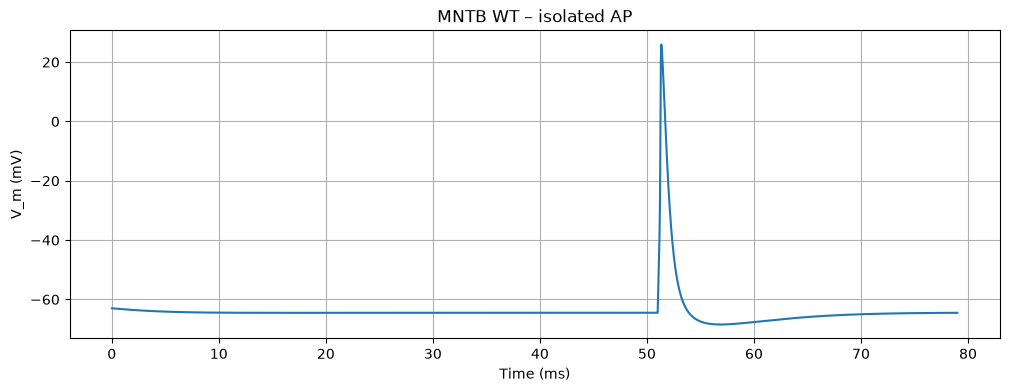

In [40]:
amp = 1400.

nest.ResetKernel()
nest.resolution = 0.01

if wt_model not in nest.node_models:
    nest.Install(str(module_path))

n = nest.Create(wt_model)

stim = nest.Create(
    "step_current_generator",
    params={
        "amplitude_times": [50., 50.25],
        "amplitude_values": [amp, 0.]
    }
)

vm = nest.Create("voltmeter", params={"interval": 0.01})

nest.Connect(stim, n)
nest.Connect(vm, n)

nest.Simulate(80.)

ev = vm.events

plt.figure(figsize=(12, 4))
plt.plot(ev["times"], ev["V_m"])
plt.xlabel("Time (ms)")
plt.ylabel("V_m (mV)")
plt.title("MNTB WT – isolated AP")
plt.grid(True)
plt.show()

In [44]:
import numpy as np
import matplotlib.pyplot as plt

def simulate_mntb(freq=None, g_HT=150., amp=1400.,
                  pulse_width=0.25, n_pulses=10):

    nest.ResetKernel()
    nest.resolution = 0.01

    if wt_model not in nest.node_models:
        nest.Install(str(module_path))

    neuron = nest.Create(wt_model, params={"g_Kv31": g_HT})

    if freq is None:
        pulse_times = np.array([50.])
    else:
        pulse_times = 50. + np.arange(n_pulses) * 1000. / freq

    pulse_times = np.round(pulse_times / 0.01) * 0.01

    amplitude_times = []
    amplitude_values = []

    for t in pulse_times:
        amplitude_times.extend([
            round(float(t), 2),
            round(float(t + pulse_width), 2)
        ])
        amplitude_values.extend([amp, 0.])

    stim = nest.Create("step_current_generator", params={
        "amplitude_times": amplitude_times,
        "amplitude_values": amplitude_values
    })

    vm = nest.Create("voltmeter", params={"interval": 0.01})

    nest.Connect(stim, neuron)
    nest.Connect(vm, neuron)

    nest.Simulate(float(pulse_times[-1] + 20.))

    ev = vm.events

    return ev["times"].copy(), ev["V_m"].copy(), pulse_times


Nov 21 18:53:56 SimulationManager::run [Warning]: 
    The requested simulation time is not an integer multiple of the minimal 
    delay in the network. This may result in inconsistent results under the 
    following conditions: (i) A network contains more than one source of 
    randomness, e.g., two different poisson_generators, and (ii) Simulate is 
    called repeatedly with simulation times that are not multiples of the 
    minimal delay.

Nov 21 18:53:57 SimulationManager::run [Warning]: 
    The requested simulation time is not an integer multiple of the minimal 
    delay in the network. This may result in inconsistent results under the 
    following conditions: (i) A network contains more than one source of 
    randomness, e.g., two different poisson_generators, and (ii) Simulate is 
    called repeatedly with simulation times that are not multiples of the 
    minimal delay.


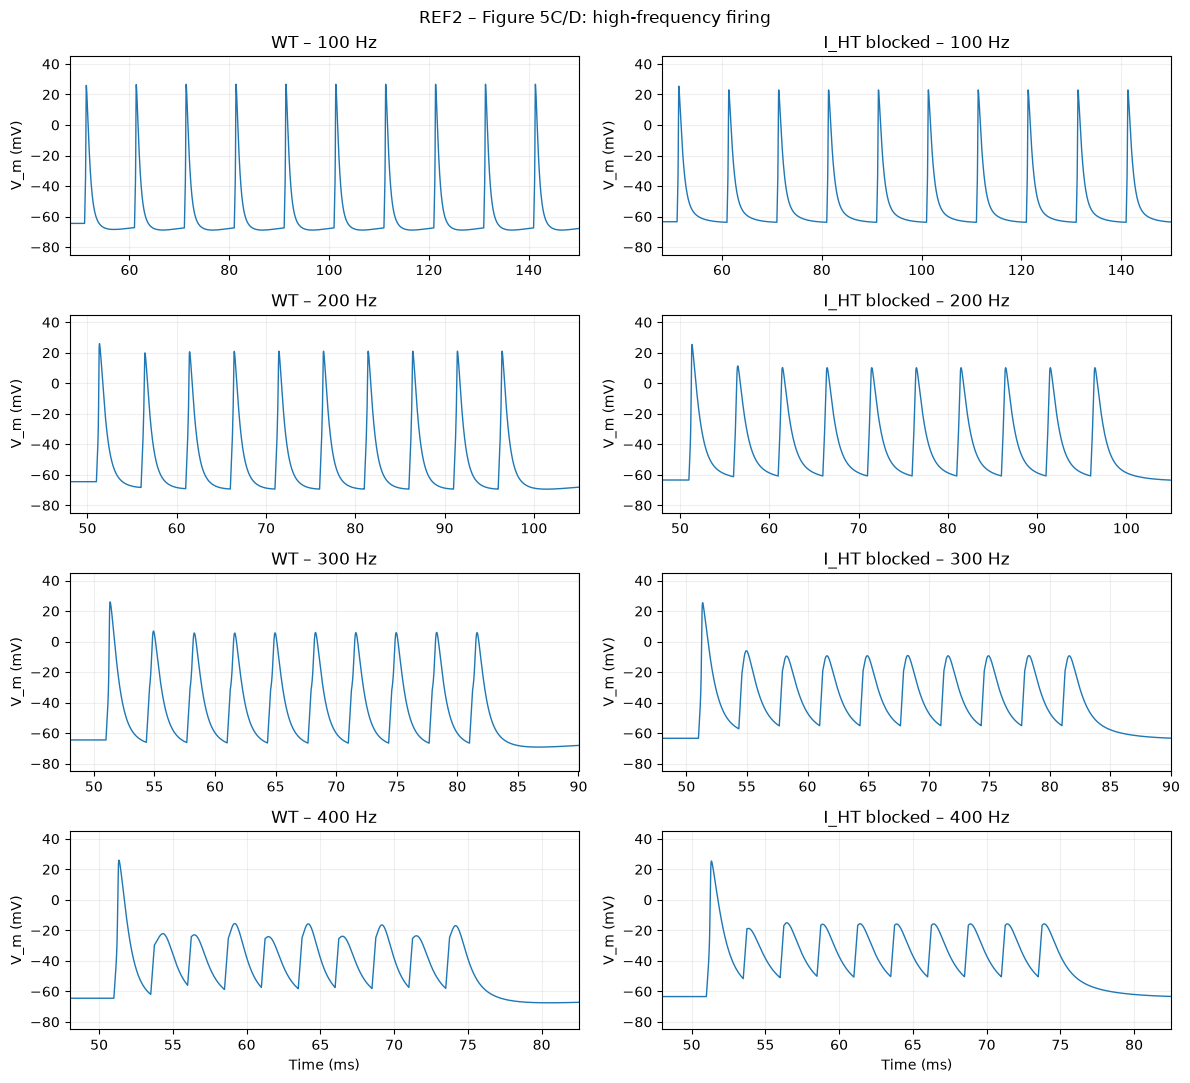

In [45]:
frequencies = [100, 200, 300, 400]
conditions = [("WT", 150.), ("I_HT blocked", 0.)]

fig, axes = plt.subplots(4, 2, figsize=(12, 11))

results = {}

for col, (label, g_HT) in enumerate(conditions):
    for row, freq in enumerate(frequencies):

        t, v, pulses = simulate_mntb(freq=freq, g_HT=g_HT)
        results[(label, freq)] = (t, v, pulses)

        ax = axes[row, col]
        ax.plot(t, v, linewidth=1)

        ax.set_xlim(48, pulses[-1] + 10)
        ax.set_ylim(-85, 45)
        ax.set_title(f"{label} – {freq} Hz")
        ax.set_ylabel("V_m (mV)")
        ax.grid(alpha=0.2)

        if row == 3:
            ax.set_xlabel("Time (ms)")

plt.suptitle("REF2 – Figure 5C/D: high-frequency firing")
plt.tight_layout()
plt.show()

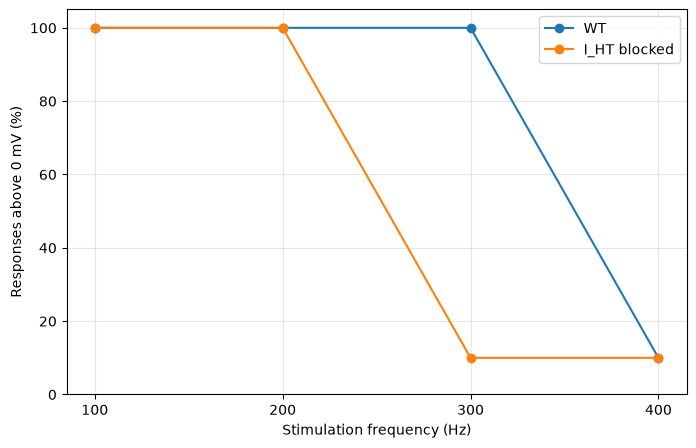

In [46]:
fig, ax = plt.subplots(figsize=(8, 5))

for label, _ in conditions:

    reliability = []

    for freq in frequencies:
        t, v, pulses = results[(label, freq)]
        period = 1000. / freq

        peaks = []

        for p in pulses:
            mask = (t >= p) & (t < p + period)
            peaks.append(np.max(v[mask]))

        reliability.append(
            100 * np.mean(np.array(peaks) > 0)
        )

    ax.plot(frequencies, reliability, "o-", label=label)

ax.set_xlabel("Stimulation frequency (Hz)")
ax.set_ylabel("Responses above 0 mV (%)")
ax.set_ylim(0, 105)
ax.set_xticks(frequencies)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

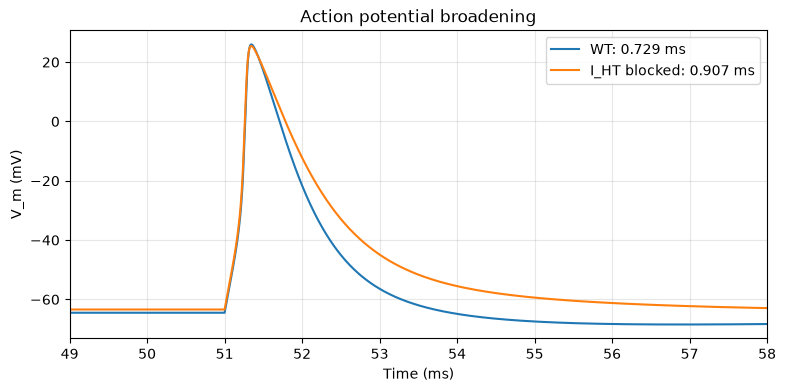

In [47]:
def ap_half_width(t, v):
    baseline = np.mean(v[(t >= 45) & (t < 50)])
    peak_idx = np.argmax(v)
    peak = v[peak_idx]
    half = baseline + (peak - baseline) / 2

    rising = np.where(v[:peak_idx] < half)[0]
    falling = np.where(v[peak_idx:] < half)[0]

    if len(rising) == 0 or len(falling) == 0:
        return np.nan

    i = rising[-1]
    j = peak_idx + falling[0]

    t_up = np.interp(half, v[i:i+2], t[i:i+2])
    t_down = np.interp(
        half, v[j-1:j+1][::-1], t[j-1:j+1][::-1]
    )

    return t_down - t_up


plt.figure(figsize=(9, 4))

for label, g_HT in conditions:
    t, v, _ = simulate_mntb(freq=None, g_HT=g_HT)

    width = ap_half_width(t, v)

    plt.plot(t, v, label=f"{label}: {width:.3f} ms")

plt.xlim(49, 58)
plt.xlabel("Time (ms)")
plt.ylabel("V_m (mV)")
plt.title("Action potential broadening")
plt.legend()
plt.grid(alpha=0.3)
plt.show()